# 17 · M1.3a · CPER 2020–2023: image verification and a real-image audit of the CRT sampler

**Purpose.** Notebook 16 validated the conditional randomisation test (CRT) on synthetic worlds only. Its validity on real data depends on whether `inference.conditional_sampler` describes the real visual features given the context. This notebook checks that **before** any zero-information test is run (M1.3).
1. **Verification** of the CPER 2020–2022 hourly images under the frozen plan ([docs/cper_2020_2023_plan.md](../docs/cper_2020_2023_plan.md), with its §9 deviations of 2026-11-01). It covers completeness, decodability and SHA-256 manifest, the burned-in camera clock, camera configuration, view and image regions, and the join with the NEON tower record. 2023 is re-verified with the same code.
2. **Features**: the nine frozen features (`features.py`), with the plan's sky rule.
3. **Sampler audit**: observed against simulated visual residuals, and a semi-synthetic null built from real images.

**No relation between a real label and a real image is examined here.** The semi-synthetic nulls of §7.3 pair the images of one year with label residuals from *another* year, so D* is independent of V given C by construction.

**Declared before this notebook was first executed (2026-11-01).**

| family | statistic per visual feature × season (residual = V − Ê[V \| C], the sampler's own fitted mean) | criterion |
|---|---|---|
| F1 persistence | lag-1 and lag-7 autocorrelation of day means; within-day lag-1 autocorrelation | share of cells outside the central 95 % band of 200 sampler draws ≤ 0.10 |
| F2 cross-feature | row-level correlation of every feature pair | same |
| F3 conditional variation | SD at hour ≥ 14 over SD at hour ≤ 9; SD in the warm over the cool temperature tercile; cross-validated R² of the residual on the raw context (40 draws) | same |
| F4 shape and tails | skewness, excess kurtosis, share of \|z\| > 3 | same |
| F5 real-image null calibration | CRT rejection rate at 0.05 over 39 semi-synthetic null datasets (real V and C, label residuals from another year) | ≤ 0.10 |

- **Decision rule.** The sampler is *suitable for exploratory testing* if F1 and F5 pass. Failures in F2–F4 are reported as limitations, with their direction.
- **If unsuitable,** no Q0 p-value is computed on the real labels (plan §9), and only per-season gains are reported.
- The F1 lag-1 statistics are partly fitted by the sampler itself (it estimates a day-level and a within-day AR(1)), so lag-7 is the informative part of F1.
- A positive control injects a visual component of about 0.03 nats into the same semi-synthetic datasets (Gaussian approximation). It is reported, not gated.

In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')

import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from PIL import Image, ImageDraw

from visual_hygrometry import data, features, inference, neon, scoring, suite, thermo, worlds

warnings.filterwarnings('ignore', message='Mean of empty slice')
plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 3)
SITE, CAM, OFF, LAT, LON = 'CPER', 'NEON.D10.CPER.DP1.00033', -7, suite.LAT, suite.LON
YEARS = [2020, 2021, 2022, 2023]
MONTHS = [f'{y}-{m:02d}' for y in YEARS for m in (6, 7, 8)]
CONFIG = ['auto_haze', 'agc', 'auto_exposure', 'wb', 'resolution', 'ir_enable', 'overlay_pos', 'mac']
B_SIM, B_R2 = 200, 40
par = lambda: Parallel(n_jobs=16, max_nbytes=None)

## 1 · Completeness, decodability and SHA-256 manifest

The frames are every listed hourly frame (on the hour, 06–19 LST) of June–August 2020–2023. Each JPEG is read once, to compute:
- its hash;
- whether it decodes at 1296 × 960;
- the digit images of its burned-in clock (§2);
- the nine features with the sky-clipping QC (§6), which involves no label.

In [2]:
F = neon.load_frames(CAM, MONTHS, OFF)
F = F[(F.base.str[-4:-2] == '00') & F.base.str[-6:-4].astype(int).between(6, 19)].reset_index(drop=True)
F['year'] = F.month.str[:4].astype(int)
F['overlay_utc'] = pd.to_datetime(F.overlay_utc, utc=True)  # NaT where .meta has no rendered time
F['has_meta'] = [(neon.RAW / 'phenocam' / CAM / m / f'{b}.meta').exists() for m, b in zip(F.month, F.base)]
F['mac'] = [neon.parse_meta((neon.RAW / 'phenocam' / CAM / m / f'{b}.meta').read_text(errors='replace')).get('mac_addr') if h else None
            for m, b, h in zip(F.month, F.base, F.has_meta)]

def frame_pass(p):
    try:
        raw = p.read_bytes()
        with Image.open(p) as im:
            im.load()
            size, gray = im.size, np.asarray(im.convert('L'))
        return dict(sha256=hashlib.sha256(raw).hexdigest(), bytes=len(raw), decodes=size == (1296, 960), digits=neon.overlay_time_digits(gray)) | features.frame_features(p, SITE)
    except Exception as e:
        return dict(decodes=False, error=f'{type(e).__name__}: {e}')

F = F.join(pd.DataFrame(par()(delayed(frame_pass)(p) for p in F.jpg[F.has_jpg]), index=F.index[F.has_jpg]))
F['decodes'] = F.decodes.fillna(False).astype(bool)
F.groupby('month').agg(hourly_listed=('base', 'size'), jpg=('has_jpg', 'sum'), meta=('has_meta', 'sum'), decodes_1296x960=('decodes', 'sum'), GB=('bytes', lambda b: b.sum() / 1e9))

,hourly_listed,jpg,meta,decodes_1296x960,GB
month,,,,,
2020-06,419,419,419,419,0.164
2020-07,427,427,427,427,0.161
2020-08,432,432,432,432,0.156
2021-06,419,419,419,419,0.158
2021-07,433,433,433,433,0.168
2021-08,377,377,377,377,0.135
2022-06,420,420,420,420,0.155
2022-07,433,433,433,433,0.155
2022-08,432,432,419,432,0.165


In [3]:
man = F[F.has_jpg & (F.year < 2023)].assign(site=SITE)[['site', 'base', 'utc', 'bytes', 'sha256']]
man.to_csv(data.ROOT / 'data' / 'manifests' / 'phenocam_hourly_CPER_2020-2022JJA.csv', index=False)
old = pd.read_csv(data.ROOT / 'data' / 'manifests' / 'phenocam_hourly_2023JJA.csv').query('site == @SITE')
chk = old.merge(F[['base', 'sha256']], on='base', how='left', suffixes=('_manifest', '_now'))
print(f'2020–2022: {len(man)} JPEGs hashed ({man.bytes.sum() / 1e9:.2f} GB), duplicate hashes {man.sha256.duplicated().sum()}; decode errors {int(F.has_jpg.sum() - F.decodes.sum())}')
print(f'2023: {len(chk)} manifest entries; on disk {chk.sha256_now.notna().sum()}; identical hash {(chk.sha256_manifest == chk.sha256_now).sum()}')

2020–2022: 3792 JPEGs hashed (1.42 GB), duplicate hashes 0; decode errors 0
2023: 1288 manifest entries; on disk 1288; identical hash 1288


## 2 · Camera clock: the burned-in overlay time

For 2020–2022 the `.meta` overlay field holds only a template (notebook 15), so the clock is read from the pixels (plan §9).
- **Reader.** The overlay is a 2× pixel font; `neon.overlay_time_digits` cuts out the six digits of hh:mm:ss.
- **Templates.** Digit templates are means over 2023 frames, whose `.meta` carries the rendered time.
- **Validation.** Templates from June 2023 only, tested on July–August 2023.
- **Declared rules.** A reading whose smallest best-to-second template margin is below 2 is unreadable. A frame passes if |overlay − file-name time| ≤ 60 s. A day with any failing frame is excluded. Unreadable frames keep the file-name time and are counted.

In [4]:
truth = F.digits.notna() & F.overlay_utc.notna() & (F.year == 2023)
def templates(rows):
    X, Y = np.vstack(F.digits[rows].tolist()), np.array(list(''.join(F.overlay_utc[rows].dt.strftime('%H%M%S'))))
    return {c: X[Y == c].mean(0) for c in '0123456789'}

def read(rows, T):
    r = [neon.read_overlay_time(d, T) for d in F.digits[rows]]
    return pd.DataFrame(r, index=F.index[rows], columns=['ocr', 'margin'])

dev = read(truth & (F.month != '2023-06'), templates(truth & (F.month == '2023-06')))
want = F.overlay_utc[dev.index].dt.strftime('%H%M%S')
digit_acc = np.mean([a == b for s, t in zip(dev.ocr, want) for a, b in zip(s, t)])
print(f'held-out 2023 (Jul–Aug, templates from June): {len(dev)} frames, digit accuracy {digit_acc:.5f}, frame accuracy {(dev.ocr == want).mean():.5f}; '
      f'frames with margin < 2: {(dev.margin < 2).sum()}, of which wrong {((dev.margin < 2) & (dev.ocr != want)).sum()}; wrong with margin ≥ 2: {((dev.margin >= 2) & (dev.ocr != want)).sum()}')
print(f'2023 frames with a .meta time but no time token found: {(F.overlay_utc.notna() & F.has_jpg & F.digits.isna() & (F.year == 2023)).sum()}')

held-out 2023 (Jul–Aug, templates from June): 850 frames, digit accuracy 0.99980, frame accuracy 0.99882; frames with margin < 2: 4, of which wrong 1; wrong with margin ≥ 2: 0
2023 frames with a .meta time but no time token found: 28


In [5]:
T_ALL = templates(truth)
F = F.join(read(F.digits.notna(), T_ALL))
F['readable'] = F.ocr.notna() & (F.margin >= 2)
sec = lambda s: int(s[:2]) * 3600 + int(s[2:4]) * 60 + int(s[4:])
fn = F.utc.dt.hour * 3600 + F.utc.dt.minute * 60 + F.utc.dt.second
F['offset_s'] = np.where(F.readable, ((F.ocr.where(F.readable, '000000').map(sec) - fn + 43200) % 86400) - 43200, np.nan)
F['local_day'] = (F.utc + pd.Timedelta(hours=OFF)).dt.tz_localize(None).dt.floor('D')
bad_days = set(F.local_day[F.offset_s.abs() > 60])
F['clock_ok'] = ~F.local_day.isin(bad_days)
F[F.has_jpg].groupby('month').agg(frames=('base', 'size'), readable=('readable', 'sum'), unreadable=('readable', lambda r: (~r).sum()),
                                   pass_60s=('offset_s', lambda o: (o.abs() <= 60).sum()), fail_60s=('offset_s', lambda o: (o.abs() > 60).sum()),
                                   max_abs_offset_s=('offset_s', lambda o: o.abs().max()), median_offset_s=('offset_s', 'median'), days_excluded=('local_day', lambda d: d[d.isin(bad_days)].nunique()))

,frames,readable,unreadable,pass_60s,fail_60s,max_abs_offset_s,median_offset_s,days_excluded
month,,,,,,,,
2020-06,419,407,12,407,0,1.0,0.0,0
2020-07,427,418,9,418,0,1.0,0.0,0
2020-08,432,430,2,430,0,1.0,0.0,0
2021-06,419,413,6,413,0,1.0,0.0,0
2021-07,433,427,6,426,1,66.0,0.0,1
2021-08,377,374,3,374,0,1.0,0.0,0
2022-06,420,413,7,413,0,6.0,0.0,0
2022-07,433,422,11,422,0,1.0,0.0,0
2022-08,432,419,13,419,0,1.0,0.0,0


In [6]:
m23 = F.readable & F.overlay_utc.notna() & (F.year == 2023)
print(f'2023, OCR against .meta time (all templates, in-sample): {(F.ocr[m23] == F.overlay_utc[m23].dt.strftime("%H%M%S")).mean():.5f} of {m23.sum()} frames')

2023, OCR against .meta time (all templates, in-sample): 1.00000 of 1259 frames


### Independent timing check: exposure against the clear-sky index

Auto-exposure responds to scene brightness. The correlation of log exposure (from `.meta`) with the clear-sky index K = SW / GHI_clear of the tower pyranometer, read at a lag around the frame time, should be most negative at lag 0 if the frame and tower clocks agree. This is a check, not a gate. Only frames with solar elevation > 10° and a `.meta` exposure are used.

,lag of most negative correlation (min),corr at lag 0,corr at best lag
2020,0,-0.748,-0.748
2021,0,-0.789,-0.789
2022,0,-0.751,-0.751
2023,0,-0.797,-0.797


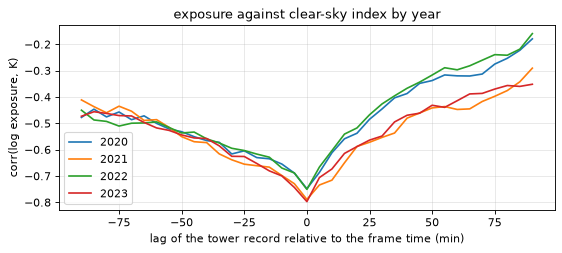

In [7]:
def labels(month):
    """The D-046 measurement model (notebooks 08, 15)."""
    s = neon.load_site(SITE, [month])
    s['D_h'], s['D_probe'] = s.t_asp - s.td, s.t_probe - s.td
    s['sd_Dh'] = np.hypot(s.td_unc / 2, s.t_asp_unc / 2)
    s['rh_implied'] = thermo.rh_from_dewpoint(s.t_probe, s.td)
    base = (s[['td_qf', 't_asp_qf', 't_probe_qf']] == 0).all(axis=1) & s[['td', 't_asp', 't_probe']].notna().all(axis=1)
    s['valid'] = base & ~(s.D_h < -2 * s.sd_Dh)
    return s

TW = pd.concat([labels(m) for m in MONTHS])

def k_at(utc, lag_min):
    t = utc.dt.floor('1min') + pd.Timedelta(minutes=lag_min)
    loc = t + pd.Timedelta(hours=OFF)
    elev = data.solar(loc.dt.day_of_year, loc.dt.hour + loc.dt.minute / 60, LAT, LON, OFF).solar_elev_deg.to_numpy()
    return data.clearsky_index(TW.sw.reindex(pd.DatetimeIndex(t)).to_numpy(), elev)

def lag_corr(e, lag):
    k = k_at(e.utc, lag)
    ok = np.isfinite(k)
    return np.corrcoef(np.log(e.exposure.to_numpy()[ok]), k[ok])[0, 1]

E = F[F.has_meta & (F.exposure > 0)]
LAGS = np.arange(-90, 91, 5)
lagc = pd.DataFrame({y: [lag_corr(e, l) for l in LAGS] for y, e in E.groupby('year')}, index=LAGS)
fig, ax = plt.subplots(figsize=(8, 3))
lagc.plot(ax=ax)
ax.set(xlabel='lag of the tower record relative to the frame time (min)', ylabel='corr(log exposure, K)', title='exposure against clear-sky index by year')
pd.DataFrame({'lag of most negative correlation (min)': lagc.idxmin(), 'corr at lag 0': lagc.loc[0], 'corr at best lag': lagc.min()})

## 3 · Camera configuration

The reference is the configuration of the 2023 frames: auto-haze, AGC, auto-exposure, white balance, resolution, IR, overlay position and the camera's MAC address. Frames without `.meta` or deviating from the reference are excluded (plan §3).

In [8]:
ref = F[F.year == 2023][CONFIG].mode().iloc[0]
F['config_ok'] = F.has_meta & (F[CONFIG] == ref).all(axis=1)
print('reference:', ref.to_dict())
pd.concat([F[F.has_meta].groupby('year')[CONFIG].nunique().add_prefix('distinct_'), F.groupby('year').agg(no_meta=('has_meta', lambda h: (~h).sum()), deviating=('config_ok', lambda c: (~c).sum()))], axis=1)

reference: {'auto_haze': '1', 'agc': '1', 'auto_exposure': '1', 'wb': '385/256/330', 'resolution': '6', 'ir_enable': '0', 'overlay_pos': '0/0/0', 'mac': '0030F4D0A44B'}


,distinct_auto_haze,distinct_agc,distinct_auto_exposure,distinct_wb,distinct_resolution,distinct_ir_enable,distinct_overlay_pos,distinct_mac,no_meta,deviating
year,,,,,,,,,,
2020,1,1,1,1,1,1,1,1,0,0
2021,1,1,1,1,1,1,1,1,0,0
2022,1,1,1,1,1,1,1,1,13,13
2023,1,1,1,1,1,1,1,1,1,1


## 4 · View and image regions

Plan §3: each season's noon frames (12:00 LST, one per day) against the 2023 reference. The phase-correlation shift of overlay-masked edge maps (4× downsampled, notebook 13) must be ≤ 8 px, and the edge correlation ≥ 0.5.
- The reference is the median 2023 noon edge map.
- A season passes if its median frame passes both criteria.
- Single cloudy or wet frames can fall below 0.5 and are listed, not excluded.

In [9]:
def edges(path):
    a = features.masked(Image.open(path).convert('RGB'))
    g = np.nan_to_num(a @ [0.2126, 0.7152, 0.0722], nan=np.nanmedian(a))
    g = g[:g.shape[0] // 4 * 4, :g.shape[1] // 4 * 4].reshape(g.shape[0] // 4, 4, g.shape[1] // 4, 4).mean((1, 3))
    e = np.hypot(*np.gradient(g))
    return (e - e.mean()) / e.std()

def shift(e, ref):
    X = np.fft.fft2(e) * np.conj(np.fft.fft2(ref))
    c = np.real(np.fft.ifft2(X / np.maximum(np.abs(X), 1e-12)))
    dy, dx = np.unravel_index(np.argmax(c), c.shape)
    dy, dx = (dy if dy < c.shape[0] // 2 else dy - c.shape[0]), (dx if dx < c.shape[1] // 2 else dx - c.shape[1])
    return 4 * dy, 4 * dx, np.corrcoef(e.ravel(), ref.ravel())[0, 1]

noon = F[F.decodes & (F.base.str[-6:-4] == '12')].copy()
EM = dict(zip(noon.index, par()(delayed(edges)(p) for p in noon.jpg)))
ref_e = np.median([EM[i] for i in noon.index[noon.year == 2023]], axis=0)
noon[['dy_px', 'dx_px', 'edge_corr']] = [shift(EM[i], ref_e) for i in noon.index]
view = noon.groupby('year').agg(frames=('base', 'size'), median_abs_dy=('dy_px', lambda x: x.abs().median()), median_abs_dx=('dx_px', lambda x: x.abs().median()),
                                max_abs_shift=('dy_px', lambda x: max(x.abs().max(), noon.dx_px[x.index].abs().max())), median_edge_corr=('edge_corr', 'median'),
                                min_edge_corr=('edge_corr', 'min'), frames_below_0_5=('edge_corr', lambda c: (c < .5).sum()))
view['season_passes'] = (view.median_edge_corr >= .5) & (view[['median_abs_dy', 'median_abs_dx']].max(axis=1) <= 8)
view

,frames,median_abs_dy,median_abs_dx,max_abs_shift,median_edge_corr,min_edge_corr,frames_below_0_5,season_passes
year,,,,,,,,
2020,91,0.0,0.0,0.0,0.687,0.565,0,True
2021,88,0.0,0.0,0.0,0.698,0.578,0,True
2022,91,0.0,0.0,0.0,0.660,0.480,1,True
2023,92,0.0,0.0,0.0,0.854,0.691,0,True


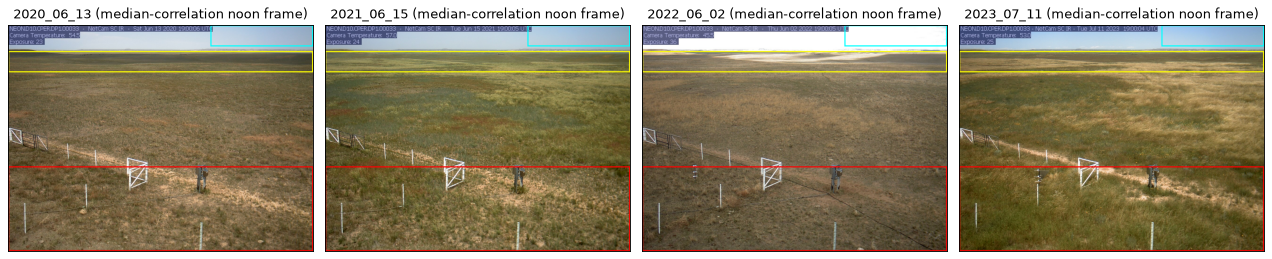

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (y, g) in zip(axes, noon.groupby('year')):
    p = g.jpg.iloc[(g.edge_corr - g.edge_corr.median()).abs().argmin()]
    im = Image.open(p).convert('RGB')
    dr = ImageDraw.Draw(im)
    for name, box in features.REGIONS[SITE].items(): dr.rectangle(box, outline={'sky': 'cyan', 'far': 'yellow', 'near': 'red'}[name], width=5)
    ax.imshow(im.reduce(2)); ax.set(title=f'{p.name[24:34]} (median-correlation noon frame)', xticks=[], yticks=[])
fig.tight_layout()

## 5 · Correspondence with the NEON tower record

Each frame joins the 1-min tower record at its UTC minute. A row is usable only if it passes every check (plan §3), which this funnel counts.

In [11]:
F['minute'] = F.utc.dt.floor('1min')
J = F.join(TW, on='minute')
steps = {'hourly JPEG': F.has_jpg, 'decodes': F.decodes, '.meta + reference config': F.decodes & F.config_ok, 'clock day passes': F.decodes & F.config_ok & F.clock_ok}
steps |= {'valid label': steps['clock day passes'] & J.valid.fillna(False).astype(bool)}
steps |= {'SW > 10 W m⁻² (usable)': steps['valid label'] & (J.sw > 10)}
pd.DataFrame({k: v.groupby(F.year).sum() for k, v in steps.items()})

,hourly JPEG,decodes,.meta + reference config,clock day passes,valid label,SW > 10 W m⁻² (usable)
year,,,,,,
2020,1278,1278,1278,1278,1271,1225
2021,1229,1229,1229,1215,1206,1166
2022,1285,1285,1272,1272,1268,1220
2023,1288,1288,1287,1287,1263,1206


In [12]:
U = J[steps['SW > 10 W m⁻² (usable)']].copy()
U['K'] = k_at(U.utc, 0)
pd.DataFrame({y: {'corr(log exposure, log SW)': np.corrcoef(np.log(u.exposure), np.log(u.sw))[0, 1], 'corr(log exposure, K)': u[['K']].assign(e=np.log(u.exposure)).corr().iloc[0, 1],
                  'corr(near-field greenness, day of year)': np.corrcoef(u.vis_near_gcc, u.local_day.dt.day_of_year)[0, 1], 'rows': len(u), 'days': u.local_day.nunique(),
                  'RH_implied ≥ 98.3 % rows': int((u.rh_implied >= 98.3).sum())} for y, u in U.groupby('year')}).T

,"corr(log exposure, log SW)","corr(log exposure, K)","corr(near-field greenness, day of year)",rows,days,RH_implied ≥ 98.3 % rows
2020,-0.979,-0.741,-0.841,1225.0,92.0,0.0
2021,-0.970,-0.787,-0.856,1166.0,88.0,1.0
2022,-0.983,-0.751,-0.274,1220.0,92.0,8.0
2023,-0.948,-0.795,-0.786,1206.0,92.0,11.0


## 6 · Features

- **Sky rule (plan §4).** Both sky features are dropped for the whole block if the median clipped-sky share exceeds 0.2 in any season.
- **2023.** Features are recomputed from the JPEGs with the same code and compared with notebook 09's table.

In [13]:
sky = U.groupby('year').qc_sky_clip.median()
VIS = [n for n in features.NAMES if not ((sky > .2).any() and n.startswith('vis_sky'))]
print('median clipped-sky share by season:', sky.round(3).to_dict(), '-> visual features:', VIS)
m1 = pd.read_csv(data.ROOT / 'data' / 'interim' / 'm1_CPER.csv')
cmp_ = U.merge(m1, on='base', suffixes=('', '_nb09'))
print(f'2023 rows in both tables: {len(cmp_)} (notebook 09: {len(m1)}, here: {(U.year == 2023).sum()}); largest absolute difference per feature:',
      {n: float(np.nanmax(np.abs(cmp_[n] - cmp_[f'{n}_nb09']))) for n in features.NAMES})
U.drop(columns=['jpg', 'digits']).to_csv(data.ROOT / 'data' / 'interim' / 'm13_CPER.csv', index=False)
U.groupby('year')[VIS].median().T

median clipped-sky share by season: {2020: 0.009, 2021: 0.001, 2022: 0.0, 2023: 0.038} -> visual features: ['vis_sky_lum', 'vis_sky_br', 'vis_far_contrast', 'vis_near_contrast', 'vis_contrast_ratio', 'vis_far_sat', 'vis_near_gcc', 'vis_near_dark', 'vis_far_sharp']
2023 rows in both tables: 1206 (notebook 09: 1206, here: 1206); largest absolute difference per feature: {'vis_sky_lum': 0.0, 'vis_sky_br': 0.0, 'vis_far_contrast': 0.0, 'vis_near_contrast': 0.0, 'vis_contrast_ratio': 0.0, 'vis_far_sat': 0.0, 'vis_near_gcc': 0.0, 'vis_near_dark': 0.0, 'vis_far_sharp': 0.0}


year,2020,2021,2022,2023
vis_sky_lum,0.846,0.844,0.770,0.862
vis_sky_br,1.048,1.024,1.114,1.066
vis_far_contrast,0.151,0.163,0.143,0.174
vis_near_contrast,0.292,0.337,0.302,0.353
vis_contrast_ratio,0.513,0.477,0.461,0.481
vis_far_sat,0.369,0.372,0.375,0.359
vis_near_gcc,0.342,0.365,0.340,0.381
vis_near_dark,0.234,0.201,0.218,0.191
vis_far_sharp,0.006,0.008,0.006,0.007


## 7 · Audit of the CRT sampler on the real features

The record has the analysis layout of notebook 16:
- season = year, unit = local day, slot = hour, week groups;
- raw context: hour, T_asp, day of year, solar elevation, daylight fraction;
- label D_h.

The sampler is fitted exactly as `suite.pipeline` fits it.

In [14]:
loc = (U.utc + pd.Timedelta(hours=OFF)).dt.tz_localize(None)
R0 = pd.DataFrame({'year': U.year.to_numpy() - 2020, 'doy': loc.dt.day_of_year.to_numpy(), 'hour_local': (loc.dt.hour + loc.dt.minute / 60).to_numpy(),
                   'day': (loc.dt.floor('D') - pd.Timestamp('2020-01-01')).dt.days.to_numpy(), 'temp_cond_c': U.t_asp.to_numpy(), 'd_ref_k': U.D_h.to_numpy()})
R0 = pd.concat([R0, U[VIS].reset_index(drop=True), data.fourier(R0.hour_local, 24, 2, 'hour'), data.solar(R0.doy, R0.hour_local, LAT, LON, OFF)], axis=1)
R0 = R0.assign(ref_sensor_id='TRAAT', cond_sensor_id='TRAAT', dos=R0.doy - pd.to_datetime((R0.year + 2020).astype(str) + '-06-01').dt.day_of_year)
yr, day, hour, temp = R0.year.to_numpy(), R0.day.to_numpy(), R0.hour_local.to_numpy(), R0.temp_cond_c.to_numpy()
wk = yr * 14 + (R0.doy.to_numpy() - suite.DOY0) // 7
RAW = R0[['hour_local', 'temp_cond_c', 'doy', 'solar_elev_deg', 'solar_dayfrac']].to_numpy()
V = R0[VIS].to_numpy()
draw = inference.conditional_sampler(V, np.c_[RAW, yr], day, hour, strata=yr, groups=wk)
stats_ = lambda Vx: inference.residual_stats(Vx - draw.f, day, hour, yr, hour, temp)
obs, sims = stats_(V), [stats_(draw(np.random.default_rng(k))) for k in range(B_SIM)]
r2 = lambda Vx: pd.Series(1 - (((Vx - draw.f) - inference.project(np.c_[RAW, yr], Vx - draw.f, wk)) ** 2).sum(0) / (((Vx - draw.f) - (Vx - draw.f).mean(0)) ** 2).sum(0),
                          index=pd.MultiIndex.from_tuples([('resid_r2', j, 'all') for j in range(len(VIS))]))
r2_sims = par()(delayed(r2)(draw(np.random.default_rng(10_000 + k))) for k in range(B_R2))
env = pd.concat([inference.envelope(obs, sims), inference.envelope(r2(V), r2_sims)])
name = lambda j: '-'.join(VIS[int(i)][4:] for i in j.split('-')) if isinstance(j, str) else VIS[j][4:]
env.index = pd.MultiIndex.from_tuples([(s, name(j), st) for s, j, st in env.index], names=['stat', 'feature', 'season'])
FAM = {'F1 persistence': ['day_lag1', 'day_lag7', 'within_lag1'], 'F2 cross-feature': ['corr'], 'F3 conditional variation': ['sd_hour', 'sd_temp', 'resid_r2'], 'F4 shape and tails': ['skew', 'kurt', 'tail3']}
by_stat = env.groupby(level=0).agg(cells=('obs', 'size'), outside=('outside', 'mean'), above_band=('obs', lambda o: (o > env.hi[o.index]).mean()),
                                   median_obs=('obs', 'median'), median_sim=('sim_median', 'median'))
by_stat.loc[[s for f in FAM.values() for s in f]]

,cells,outside,above_band,median_obs,median_sim
stat,,,,,
day_lag1,36,0.000,0.000,0.375,0.253
day_lag7,36,0.111,0.083,0.002,-0.016
within_lag1,36,1.000,1.000,0.222,0.087
corr,144,0.000,0.000,-0.030,-0.026
sd_hour,36,0.861,0.861,1.418,1.000
sd_temp,36,0.722,0.361,0.987,1.001
resid_r2,9,0.889,0.000,-0.500,-0.136
skew,36,0.722,0.528,0.255,0.001
kurt,36,0.972,0.972,3.801,-0.027


In [15]:
fam = pd.DataFrame({f: dict(cells=int(env.loc[s].shape[0]), outside=env.loc[s].outside.mean()) for f, s in FAM.items()}).T
fam['passes (≤ 0.10)'] = fam.outside <= .10
fam

,cells,outside,passes (≤ 0.10)
F1 persistence,108.0,0.370,False
F2 cross-feature,144.0,0.000,True
F3 conditional variation,81.0,0.802,False
F4 shape and tails,108.0,0.880,False


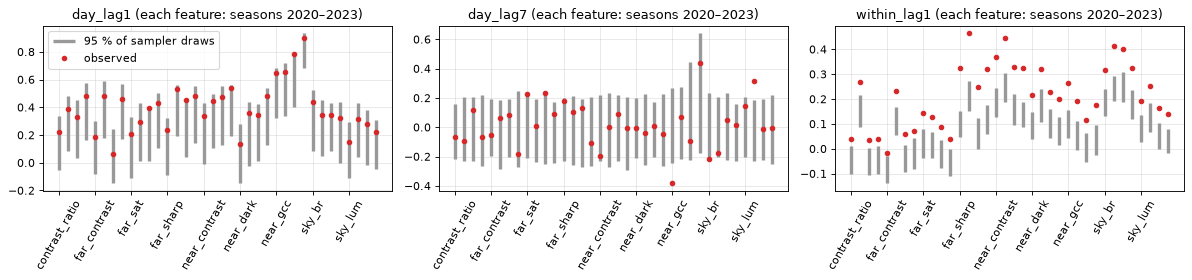

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, st in zip(axes, ['day_lag1', 'day_lag7', 'within_lag1']):
    e = env.loc[st].sort_index().reset_index()
    x = np.arange(len(e))
    ax.vlines(x, e.lo, e.hi, color='0.6', lw=3, label='95 % of sampler draws')
    ax.plot(x, e.obs, 'o', ms=4, color='C3', label='observed')
    ax.set(title=f'{st} (each feature: seasons 2020–2023)', xticks=x[::len(YEARS)], xticklabels=e.feature[::len(YEARS)])
    ax.tick_params(axis='x', rotation=60)
axes[0].legend()
fig.tight_layout()

In [17]:
pd.set_option('display.max_rows', 200)
env[env.outside].sort_values('p')

,,,obs,sim_median,lo,hi,p,outside
stat,feature,season,,,,,,
within_lag1,sky_lum,0,0.190,8.613e-02,2.579e-02,1.351e-01,0.010,True
sd_hour,sky_lum,0,2.154,9.995e-01,9.076e-01,1.099e+00,0.010,True
sd_temp,sky_lum,0,1.393,9.926e-01,9.014e-01,1.113e+00,0.010,True
kurt,sky_lum,0,1.314,-3.879e-02,-2.458e-01,2.807e-01,0.010,True
tail3,sky_lum,0,0.012,2.449e-03,0.000e+00,4.898e-03,0.010,True
within_lag1,sky_br,0,0.316,1.817e-01,1.313e-01,2.400e-01,0.010,True
sd_hour,sky_br,0,1.338,1.003e+00,9.190e-01,1.105e+00,0.010,True
skew,sky_br,0,0.772,-5.484e-03,-1.948e-01,1.730e-01,0.010,True
kurt,sky_br,0,2.788,-3.269e-02,-3.121e-01,1.901e-01,0.010,True


### 7.3 · Semi-synthetic real-image nulls (F5) and a positive control

Every dataset keeps the real images V and context C of all four seasons and replaces the label of season y by:
- D* = M₋ᵧ(C) + r, where M₋ᵧ is the ridge context model (S4 basis) fitted on the *other* three seasons;
- r is the residual D − M₋ᵧ(C) of season (y + k) mod 4, taken at the same hour, `o` days later in its season (wrapping within June–August).

Everything that builds the label of season y comes from other seasons, so D* is independent of V given C as long as seasons are independent: E2 = 0 exactly. The residuals keep the real persistence, regimes and tails of D.
- There are 39 datasets: k ∈ {1, 2, 3} × o ∈ {0, 7, …, 84} days. They are not independent, because they share V.
- Rows without a source residual at that hour are dropped from that dataset.
- The positive control adds b · z to D*. Here z is the standardised first principal component of the observed visual residuals, and b = σ_r √(e^0.06 − 1), which gives about 0.03 nats if everything were Gaussian.
- Each dataset runs the full `suite.pipeline` with its validated settings (39 CRT draws, 39 shifts).

In [18]:
dfl, lv = worlds.add_context_levels(R0, suite.KNOTS, suite.DOY_K, suite.DOY_F, hour_season=True, solar=True)
X4, D = dfl[lv['S4']].to_numpy(), R0.d_ref_k.to_numpy()
M = {y: scoring.ridge_fit(X4, D, yr != y, wk)['predict'](X4) for y in range(4)}
key = pd.Series(np.arange(len(R0)), index=pd.MultiIndex.from_arrays([yr, R0.dos, R0.hour_local.round().astype(int)]))
key = key[~key.index.duplicated()]

def null_label(k, o):
    out = np.full(len(R0), np.nan)
    for y in range(4):
        rows = np.flatnonzero(yr == y)
        src = key.reindex(pd.MultiIndex.from_arrays([np.full(len(rows), (y + k) % 4), (R0.dos.to_numpy()[rows] + o) % 92, R0.hour_local.round().astype(int).to_numpy()[rows]])).to_numpy()
        ok = ~np.isnan(src)
        out[rows[ok]] = M[y][rows[ok]] + (D - M[y])[src[ok].astype(int)]
    return out

Rv = V - draw.f
pc1 = np.linalg.svd((Rv - Rv.mean(0)) / Rv.std(0), full_matrices=False)[0][:, 0]
z = (pc1 - pc1.mean()) / pc1.std()
b = np.std(D - M[0]) * np.sqrt(np.exp(.06) - 1)
W = {'vis': VIS, 'shared_sensor': True}

def semi(k, o, signal):
    y = null_label(k, o) + signal * b * z
    m = np.isfinite(y)
    out = suite.pipeline(R0[m].reset_index(drop=True).assign(d_ref_k=y[m]), W)
    return dict(k=k, o=o, signal=signal, rows=int(m.sum()), est=out['est'], p_crt=out['p_crt'], p_shift=out['p_shift'], repair_lb=out['repair_lb'])

SEMI = pd.DataFrame(par()(delayed(semi)(k, o, s) for s in (0, 1) for k in (1, 2, 3) for o in range(0, 85, 7)))
SEMI.groupby('signal').agg(datasets=('k', 'size'), rows=('rows', 'median'), rej_crt=('p_crt', lambda p: (p <= .05).mean()), rej_shift=('p_shift', lambda p: (p <= .05).mean()),
                           median_p_crt=('p_crt', 'median'), mean_est=('est', 'mean'), repair_flag=('repair_lb', lambda l: (l > .002).mean())).rename(index={0: 'null (E2 = 0)', 1: 'injected ≈ 0.03 nats'})

,datasets,rows,rej_crt,rej_shift,median_p_crt,mean_est,repair_flag
signal,,,,,,,
null (E2 = 0),39,4570.0,0.026,0.077,0.525,-4.227e-03,0.000
injected ≈ 0.03 nats,39,4570.0,0.282,0.436,0.225,5.461e-04,0.026


### Decision (rule declared above)

In [19]:
f5 = (SEMI[SEMI.signal == 0].p_crt <= .05).mean()
suitable = bool(fam.loc['F1 persistence', 'passes (≤ 0.10)'] and f5 <= .10)
print(f'F1 persistence: {fam.loc["F1 persistence", "outside"]:.3f} of cells outside (≤ 0.10: {fam.loc["F1 persistence", "passes (≤ 0.10)"]}); '
      f'F5 real-image null CRT rejection {f5:.3f} (≤ 0.10: {f5 <= .10}) -> sampler suitable for exploratory testing: {suitable}')
print('limitations (F2–F4 failing):', [f for f in ['F2 cross-feature', 'F3 conditional variation', 'F4 shape and tails'] if not fam.loc[f, 'passes (≤ 0.10)']])

F1 persistence: 0.370 of cells outside (≤ 0.10: False); F5 real-image null CRT rejection 0.026 (≤ 0.10: True) -> sampler suitable for exploratory testing: False
limitations (F2–F4 failing): ['F3 conditional variation', 'F4 shape and tails']


## 8 · Reading

**Verification: the 2020–2022 images are complete and consistent with 2023 and with the tower record.**
1. **Files.**
   - All 3,792 hourly JPEGs listed for 2020–2022 are on disk and decode at 1296 × 960 (1.42 GB), with no duplicate hashes. The SHA-256 manifest is `data/manifests/phenocam_hourly_CPER_2020-2022JJA.csv`.
   - The 1,288 CPER frames of 2023 still match notebook 09's manifest hash for hash.
   - 14 frames have no `.meta` on the server (13 in August 2022, 1 in June 2023) and are excluded.
2. **Clock.**
   - *Reader validation.* On 850 held-out 2023 frames the overlay reader is right for 99.98 % of digits and 99.88 % of frames. Its only error had a margin below 2, so the declared rule treats it as unreadable.
   - *Unreadable frames.* 2–3 % per month (2–13 frames), mostly where no time token is segmented. They keep the file-name time.
   - *Agreement.* Every other readable frame of 2020–2022 agrees with its file-name time within 1 s, except one at 6 s (June 2022) and one at 66 s (9 July 2021).
   - *The 66 s frame is a misread.* Inspection shows the overlay reads 20:00:05, the file-name time, but the reader returned 20:01:11 with margin 6.2. Under the declared rule its day (14 frames) is excluded anyway; the exclusion is conservative and was not reversed after the fact. The reader's confident-error rate on 2020–2022 is therefore at least 1 in about 3,700 frames.
   - *Independent check.* The correlation of log exposure with the clear-sky index is most negative at lag 0 in every year (−0.75 to −0.80), so frame and tower clocks agree to within the 5-min resolution of this check.
3. **Configuration.** Every frame with a `.meta` file has the 2023 configuration and the same camera unit (MAC 0030F4D0A44B).
4. **View.** No phase-correlation shift in any noon frame of any year (0 px). The median edge correlation against the 2023 reference is 0.66–0.70 in 2020–2022 (0.85 in 2023, the reference year itself); one 2022 frame is at 0.48. Every season passes, and the frozen regions sit on the same scene features.
5. **Tower join.**
   - Usable rows: 1,225 (2020), 1,166 (2021), 1,220 (2022) and 1,206 (2023), with 88–92 days per season.
   - Log exposure tracks log SW (correlation −0.95 to −0.98).
   - Near-field greenness falls through the summer in 2020, 2021 and 2023 (correlation with day of year −0.79 to −0.86) but hardly in 2022 (−0.27). The phenology differs between years, which is a reason for season-specific context terms.
   - RH_implied ≥ 98.3 % occurs in 0 / 1 / 8 / 11 rows.
6. **Features.** The sky rule keeps both sky features (median clipped share 0.00–0.04). The recomputed 2023 features equal notebook 09's exactly.

**Sampler audit: by the declared rule, the CRT sampler is not suitable for exploratory testing (F1 fails).**

| family | share of cells outside the 95 % band | criterion | what differs |
|---|---|---|---|
| F1 persistence | 0.37 | **fail** | day-level lag 1: 0 of 36 outside; lag 7: 4 of 36 (0.11); **within-day lag 1: 36 of 36**, observed median 0.22 against 0.09 simulated |
| F2 cross-feature | 0.00 | pass | the correlated innovations reproduce feature correlations |
| F3 conditional variation | 0.80 | fail | residual SD 1.4× higher after 14 h than before 10 h (31 of 36 outside); temperature-tercile SD ratios outside in both directions; observed residuals are *less* predictable from C than simulated ones (R² −0.50 vs −0.14), the boosted cross-fit chasing heavy tails |
| F4 shape and tails | 0.88 | fail | excess kurtosis median 3.8 (up to 25); right skew; 1.5 % of rows beyond 3 SD against 0.2 % |
| F5 real-image null | CRT rejection 0.026 (1 of 39) | pass | shift test 0.077 (3 of 39) |

- **Why within-day persistence is too weak.** The within-day AR(1) coefficient is estimated from deviations from each day's mean, over about 13 hourly rows. That lag-1 estimate is biased downward and is not corrected, unlike the day-level estimate (Kendall). The sampler therefore simulates with about 0.22, and its draws, after the same day-demeaning, show about 0.09. This follows from the construction in `conditional_sampler`; the real data exposed it, the synthetic suite did not.
- **Hour, temperature and tails.** The innovations are Gaussian with one scale per season. The real residuals are heteroscedastic by hour and by temperature and heavy-tailed, plausibly from afternoon convective cloud.
- **F5 passed despite the misfit.** On 39 semi-synthetic nulls with real images, the CRT was not anti-conservative (0.026). Those datasets share one V and are strongly dependent, so 39 of them cannot show nominal Type I. This low resolution is why F1 was made part of the rule.
- **Power is low on real data.** With the injected component of about 0.03 nats (Gaussian approximation), the CRT rejected in 0.28 of datasets and the shift test in 0.44. The mean estimated contrast rose by only 0.005 nats, so the injected component is far from 0.03 nats once real tails and the ridge joint model are involved.

**Consequence (plan §9, 2026-11-01).** No zero-information p-value is computed on the real labels. Notebook 18 reports the per-season predictive gains descriptively, with the repair diagnostic and sensitivities, and without any test or interval. A corrected sampler would have to be developed and validated synthetically, and then re-audited on these features, before Q0 is attempted. That is a decision for the independent review.